In [49]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns


In [50]:
fuel_data = pd.read_csv("military_aircraft_fuel_regression.csv")

work_fuel_data = fuel_data.dropna(axis=0)

target = "Mission_Fuel_Consumption_Liters"

correlation = work_fuel_data.corr(numeric_only = True)

print(correlation[target]
      .drop(target)
      .sort_values(key = abs , ascending = False )
      )

the_final_data = work_fuel_data.drop(
    columns=[
       
        "Wind_Speed_kmh"
    ]
)

print(the_final_data)


Aircraft_Age_Years             0.186331
Payload_kg                     0.160474
Cruise_Speed_kmh               0.138001
Maintenance_Hours_Last_Year    0.131796
Wind_Speed_kmh                 0.080946
Total_Flight_Hours             0.066780
Outside_Temperature_C          0.009018
Name: Mission_Fuel_Consumption_Liters, dtype: float64
     Aircraft_Type  Aircraft_Age_Years  Total_Flight_Hours  Payload_kg  \
0           Patrol                16.4              2025.3      1852.4   
1          Trainer                10.1               614.7      1766.2   
2        Transport                 9.1              1368.4      2601.3   
3        Transport                 0.5               671.6      2496.5   
4          Trainer                14.4              1256.8      1639.8   
...            ...                 ...                 ...         ...   
7995     Transport                27.5              2126.2      2625.5   
7996       Trainer                13.3              5579.6      1788.0   


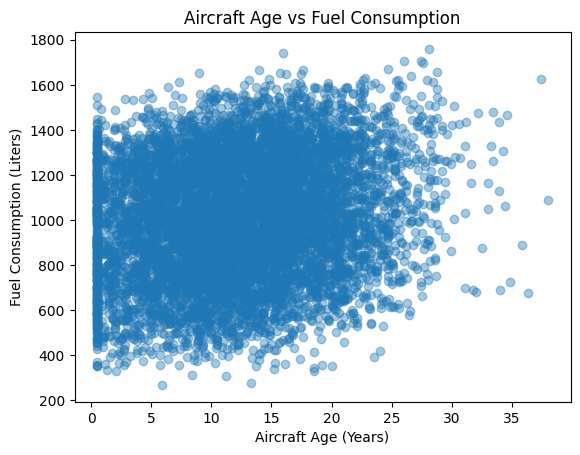

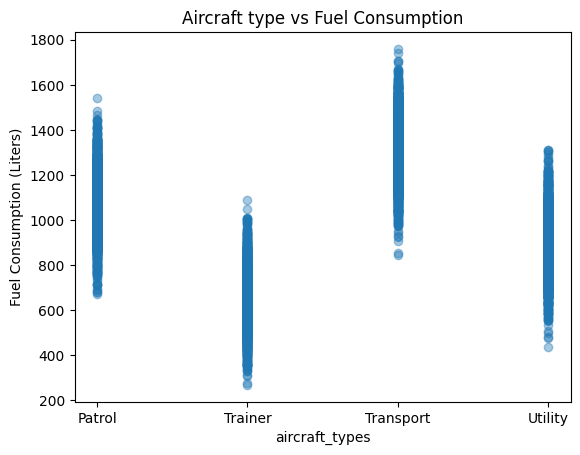

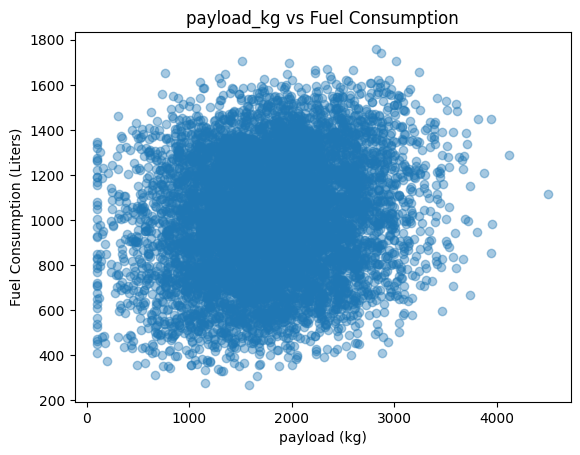

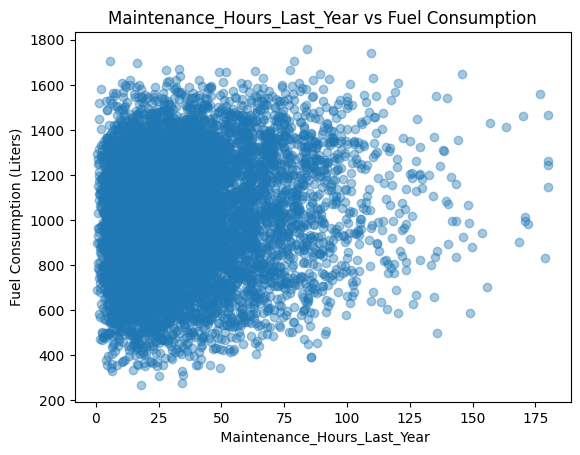

In [51]:
plt.scatter(
    the_final_data["Aircraft_Age_Years"],
    the_final_data["Mission_Fuel_Consumption_Liters"],
    alpha=0.4,
)

plt.xlabel("Aircraft Age (Years)")
plt.ylabel("Fuel Consumption (Liters)")
plt.title("Aircraft Age vs Fuel Consumption")


plt.show()
plt.scatter(
    the_final_data["Aircraft_Type"],
    the_final_data["Mission_Fuel_Consumption_Liters"],
    alpha=0.4
)

plt.xlabel("aircraft_types")
plt.ylabel("Fuel Consumption (Liters)")
plt.title("Aircraft type vs Fuel Consumption")

plt.show()

plt.scatter(
    the_final_data["Payload_kg"],
    the_final_data["Mission_Fuel_Consumption_Liters"],
    alpha=0.4
)

plt.xlabel("payload (kg)")
plt.ylabel("Fuel Consumption (Liters)")
plt.title("payload_kg vs Fuel Consumption")

plt.show()


plt.scatter(
    the_final_data["Maintenance_Hours_Last_Year"],
    the_final_data["Mission_Fuel_Consumption_Liters"],
    alpha=0.4
)

plt.xlabel(" Maintenance_Hours_Last_Year")
plt.ylabel("Fuel Consumption (Liters)")
plt.title("Maintenance_Hours_Last_Year vs Fuel Consumption")

plt.show()


In [52]:
mapping = {
    "Patrol": 0,
    "Trainer": 1,
    "Transport": 2,
    "Utility":3
}

the_final_data["Aircraft_Type"] = the_final_data["Aircraft_Type"].replace(mapping)

print(the_final_data["Aircraft_Type"].to_string())

0       0
1       1
2       2
3       2
4       1
5       3
6       2
7       3
8       0
9       3
10      2
11      0
12      2
13      2
14      3
15      3
16      3
17      3
18      1
19      0
20      0
21      0
22      0
23      3
24      2
25      3
26      1
27      1
28      0
29      3
31      3
32      1
33      3
34      0
35      2
36      1
37      3
38      3
39      3
40      0
41      0
42      1
43      0
44      1
45      0
46      3
47      0
48      2
49      2
50      0
51      1
52      0
53      3
54      3
55      2
56      3
57      2
58      2
59      3
60      2
61      0
62      2
63      3
64      2
65      1
66      3
67      3
68      0
69      0
70      3
71      0
72      2
73      2
74      0
75      3
76      1
77      2
78      1
79      2
80      0
81      1
82      3
83      0
84      3
85      1
86      1
87      0
88      3
89      2
90      1
91      3
92      1
93      3
94      0
95      0
96      2
97      3
98      2
99      1
100     0


C:\Users\ainzo\AppData\Local\Temp\ipykernel_20096\3880691207.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  the_final_data["Aircraft_Type"] = the_final_data["Aircraft_Type"].replace(mapping)


In [58]:
x = the_final_data[
    [
        "Aircraft_Age_Years",
        "Aircraft_Type",
        "Maintenance_Hours_Last_Year",
        "Payload_kg",
        "Total_Flight_Hours",
        'Cruise_Speed_kmh' ,
        "Outside_Temperature_C"
    ]
]

y = the_final_data["Mission_Fuel_Consumption_Liters"]


x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.3,
    random_state=50
)

model = LinearRegression()
model.fit(x_train , y_train)

predictions = model.predict(x_test)

print("Actual values:", y_test.values)
print("Predicted values:", predictions)

mae = mean_absolute_error(y_test , predictions)
print("eror:", mae)

train_prediction = model.predict(x_train)
train_mae = mean_absolute_error(y_train , train_prediction)

print('train:', train_mae)

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="mean")

baseline.fit(x_train, y_train)

baseline_predictions = baseline.predict(x_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

print("Baseline MAE:", baseline_mae)

Actual values: [ 799.4  727.7  515.8 ...  438.9 1115.3 1260.4]
Predicted values: [ 950.23296586  991.41489756  969.28863641 ...  921.32029518  996.64920084
 1065.79267121]
eror: 209.3496356152505
train: 214.65300423686077
Baseline MAE: 218.35746485535387


In [57]:
print(the_final_data["Mission_Fuel_Consumption_Liters"].describe())

count    7880.000000
mean     1008.603426
std       268.173681
min       268.500000
25%       807.700000
50%      1008.350000
75%      1220.725000
max      1759.200000
Name: Mission_Fuel_Consumption_Liters, dtype: float64


In [54]:
medin = the_final_data["Mission_Fuel_Consumption_Liters"].median()

print(medin)

print("Mean:", the_final_data["Mission_Fuel_Consumption_Liters"].mean())
print("Median:", the_final_data["Mission_Fuel_Consumption_Liters"].median())
print(the_final_data.columns.tolist())

1008.3499999999999
Mean: 1008.6034263959391
Median: 1008.3499999999999
['Aircraft_Type', 'Aircraft_Age_Years', 'Total_Flight_Hours', 'Payload_kg', 'Cruise_Speed_kmh', 'Outside_Temperature_C', 'Maintenance_Hours_Last_Year', 'Mission_Fuel_Consumption_Liters']
